In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/online_retail_cleaned.csv",
    parse_dates=["InvoiceDate"],
    dtype={"Customer ID": "Int64"}
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [2]:
df.shape

(1033036, 9)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1033036 entries, 0 to 1033035
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  str           
 1   StockCode    1033036 non-null  str           
 2   Description  1031735 non-null  str           
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[us]
 5   Price        1033036 non-null  float64       
 6   Customer ID  797885 non-null   Int64         
 7   Country      1033036 non-null  str           
 8   Revenue      1033036 non-null  float64       
dtypes: Int64(1), datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 71.9 MB


## 1. Overall Sales Overview

This section analyzes total revenue, total quantity sold, number of invoices, and the overall transaction period.

In [4]:
total_revenue = df["Revenue"].sum()
total_quantity = df["Quantity"].sum()
total_invoices = df["Invoice"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Invoices:", total_invoices)
print("Unique Customers:", total_customers)

Total Revenue: 18855533.7
Total Quantity Sold: 10409779
Total Invoices: 53628
Unique Customers: 5942


In [5]:
print("Start Date:", df["InvoiceDate"].min())
print("End Date:", df["InvoiceDate"].max())

Start Date: 2009-12-01 07:45:00
End Date: 2011-12-09 12:50:00


## 2. Monthly Revenue Trend

This section analyzes monthly revenue to identify sales trends and seasonal patterns over time.

In [6]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()

monthly_revenue.head()

YearMonth
2009-12    796648.500
2010-01    622479.502
2010-02    531265.366
2010-03    763247.241
2010-04    587926.692
Freq: M, Name: Revenue, dtype: float64

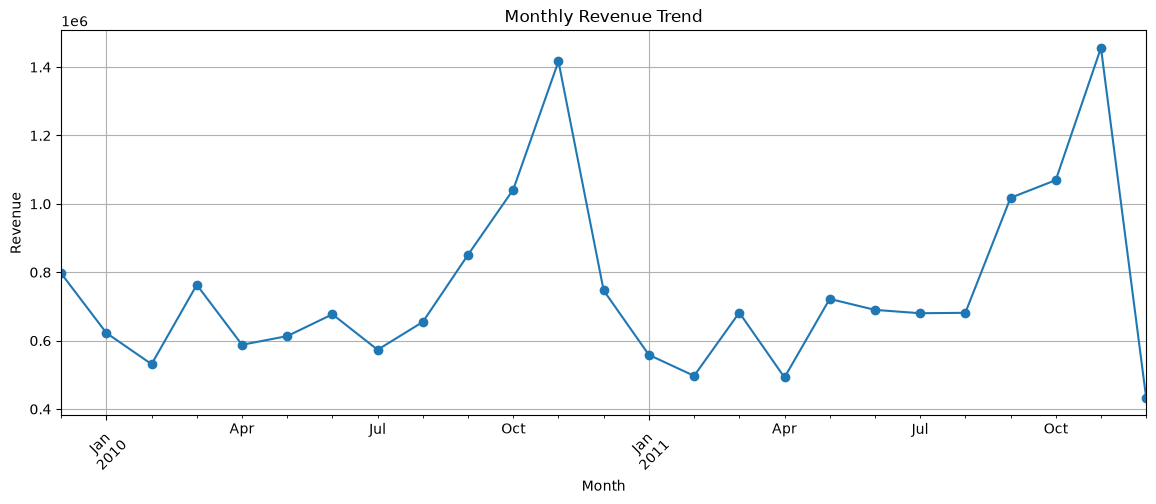

In [7]:
plt.figure(figsize=(14, 5))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

## 3. Country-wise Revenue Analysis

This section identifies the countries contributing the highest revenue.

In [8]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    1.598606e+07
EIRE              6.099538e+05
Netherlands       5.483307e+05
Germany           4.119592e+05
France            3.217334e+05
Australia         1.664444e+05
Switzerland       9.940306e+04
Spain             9.101344e+04
Sweden            8.777552e+04
Denmark           6.445959e+04
Name: Revenue, dtype: float64

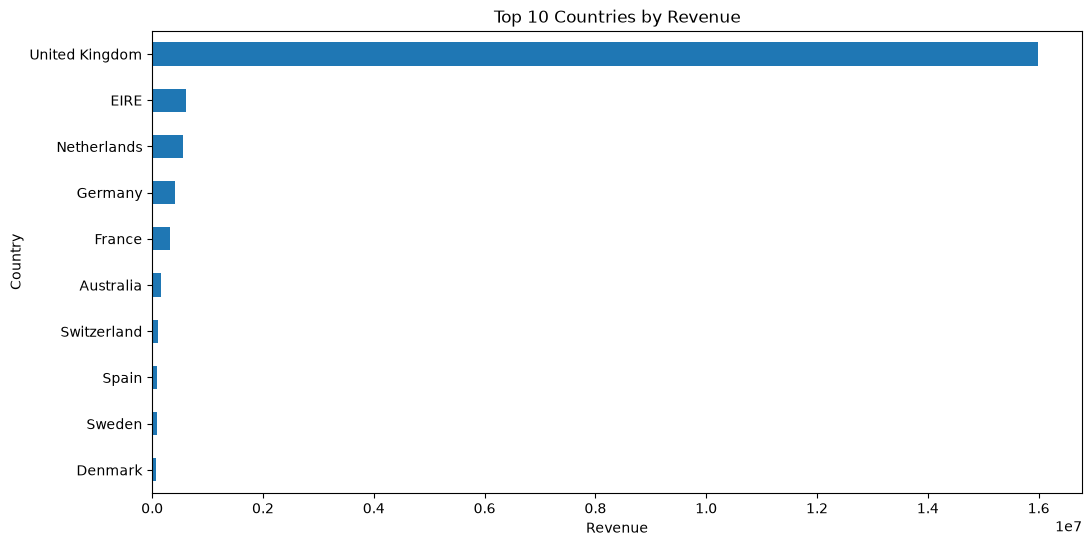

In [9]:
plt.figure(figsize=(12, 6))

country_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.show()

## 4. Top Products by Revenue

This section identifies the products generating the highest revenue.

In [10]:
product_revenue = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10)

Description
REGENCY CAKESTAND 3 TIER               314045.02
DOTCOM POSTAGE                         309844.10
WHITE HANGING HEART T-LIGHT HOLDER     251603.12
PARTY BUNTING                          147079.73
JUMBO BAG RED RETROSPOT                145946.05
ASSORTED COLOUR BIRD ORNAMENT          128550.42
PAPER CHAIN KIT 50'S CHRISTMAS         116298.59
POSTAGE                                110430.41
CHILLI LIGHTS                           79905.13
ROTATING SILVER ANGELS T-LIGHT HLDR     70969.95
Name: Revenue, dtype: float64

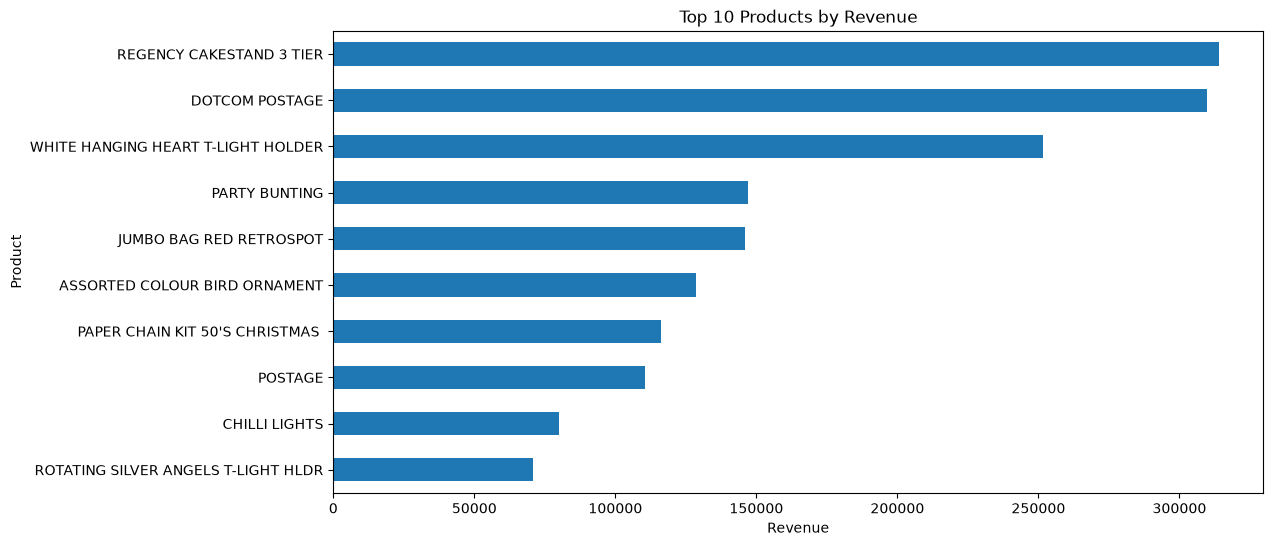

In [11]:
plt.figure(figsize=(12, 6))

product_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

## 5. Top Products by Quantity Sold

This section identifies the products with the highest total quantity sold.

In [12]:
product_quantity = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

product_quantity.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     104546
WHITE HANGING HEART T-LIGHT HOLDER     91026
ASSORTED COLOUR BIRD ORNAMENT          79579
JUMBO BAG RED RETROSPOT                76514
BROCADE RING PURSE                     69639
PACK OF 60 PINK PAISLEY CAKE CASES     55842
60 TEATIME FAIRY CAKE CASES            53678
SMALL POPCORN HOLDER                   48234
PACK OF 72 RETROSPOT CAKE CASES        47695
PACK OF 72 RETRO SPOT CAKE CASES       46079
Name: Quantity, dtype: int64

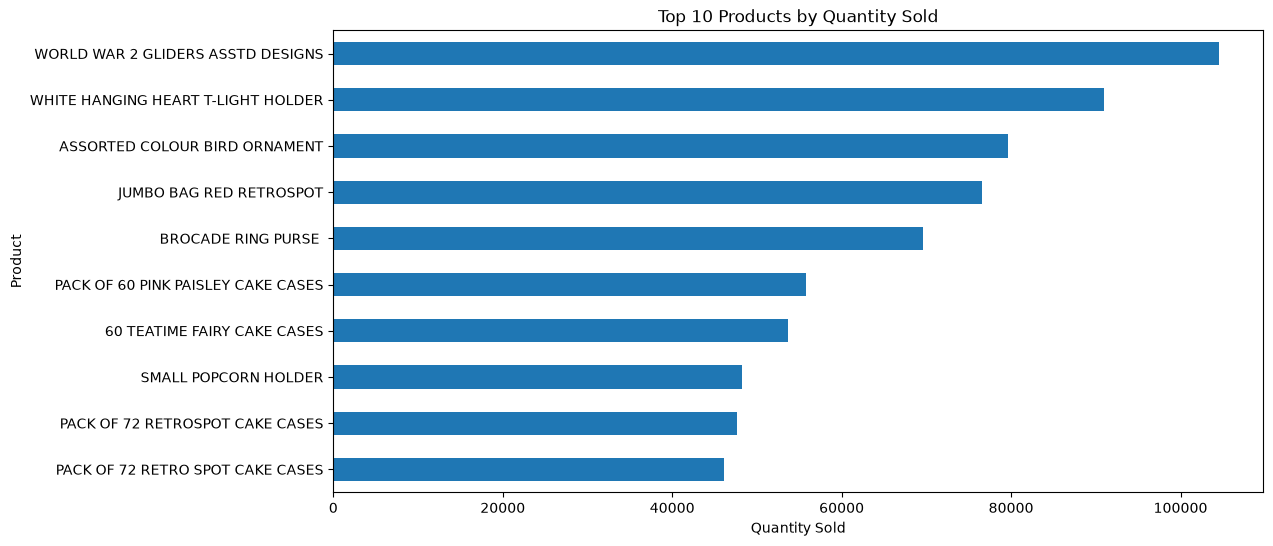

In [14]:
plt.figure(figsize=(12, 6))

product_quantity.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.show()

## 6. Customer Analysis

This section analyzes customer contribution to revenue and identifies the highest-value customers.

In [15]:
customer_revenue = (
    df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

customer_revenue.head(10)

Customer ID
18102    570380.61
14646    523342.07
14156    296063.44
14911    265757.91
17450    231390.55
13694    190020.84
17511    168491.62
12415    143269.29
16684    141502.25
15061    124961.98
Name: Revenue, dtype: float64

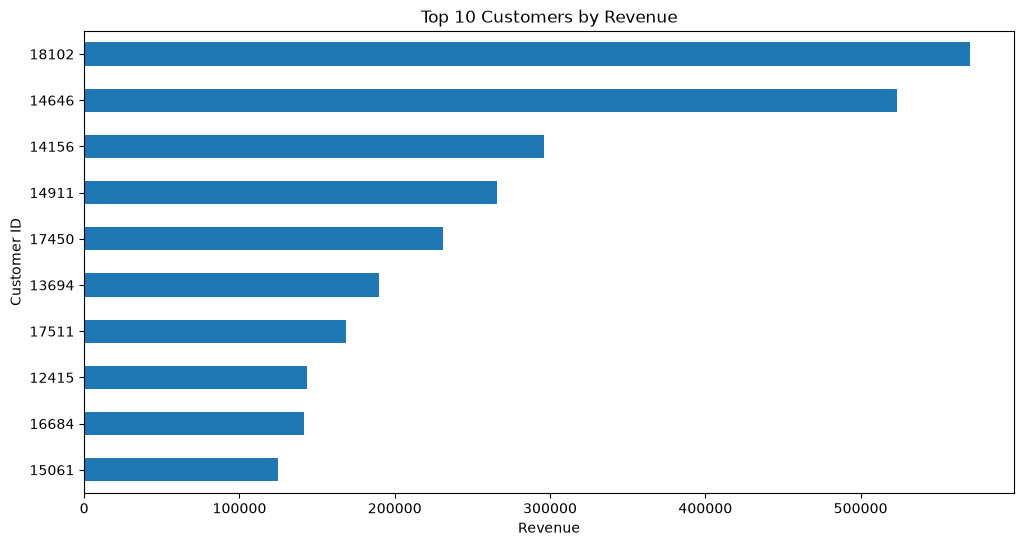

In [16]:
plt.figure(figsize=(12, 6))

customer_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")

plt.show()

## 7. Repeat Customer Analysis

This section identifies one-time and repeat customers based on the number of unique invoices.

In [17]:
customer_invoices = (
    df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

repeat_customers = (customer_invoices > 1).sum()
one_time_customers = (customer_invoices == 1).sum()

print("Total Customers:", len(customer_invoices))
print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)
print("Repeat Customer Rate:", round(repeat_customers / len(customer_invoices) * 100, 2), "%")

Total Customers: 5942
Repeat Customers: 4481
One-time Customers: 1461
Repeat Customer Rate: 75.41 %


## 8. Returns and Cancellations Analysis

This section examines negative quantities and cancellation invoices to understand product returns and cancelled transactions.

In [18]:
negative_quantity = df[df["Quantity"] < 0]

cancellation_invoices = df[
    df["Invoice"].str.startswith("C", na=False)
]

print("Negative Quantity Records:", len(negative_quantity))
print("Cancellation Invoice Records:", len(cancellation_invoices))
print("Revenue from Negative Quantity:", round(negative_quantity["Revenue"].sum(), 2))

Negative Quantity Records: 22496
Cancellation Invoice Records: 19104
Revenue from Negative Quantity: -1462424.18


In [19]:
cancellation_revenue = cancellation_invoices["Revenue"].sum()

print("Cancellation Revenue:", round(cancellation_revenue, 2))

Cancellation Revenue: -1462050.61


In [20]:
non_cancellation_returns = negative_quantity[
    ~negative_quantity["Invoice"].str.startswith("C", na=False)
]

print("Negative Quantity without C Invoice:", len(non_cancellation_returns))

Negative Quantity without C Invoice: 3393


## 9. EDA Summary

This section summarizes the key findings from the exploratory data analysis.

### Key Findings

- The dataset contains 1,033,036 records and covers transactions from December 2009 to December 2011.
- Total recorded revenue is 18.86 million, before separately handling returns and accounting adjustments.
- November shows a strong revenue peak in both 2010 and 2011.
- The United Kingdom is the largest revenue-contributing country.
- Regency Cake stand is the highest revenue-generating product in the initial product analysis.
- World War 2 Gliders Assorted Designs has the highest total quantity sold.
- The dataset contains 5,942 identified customers, of which 75.41% made purchases across multiple invoices.
- Negative quantity transactions account for approximately -1.46 million in revenue.
- Customer-level analysis excludes records with missing Customer IDs.

## 10. Key Business Insights

The exploratory analysis was conducted to identify revenue trends, product performance, country-wise contribution, customer behavior, and transaction patterns. The findings will be used to identify business opportunities and support management decisions.